# 02 — Comparación de estimadores de pitch y decisión sonoro/sordo para LPC10

**TPI Señales y Sistemas 2026 — Grupo 3: Codificación de la voz**

Siguiendo la devolución del tutor, se comparan tres métodos para el bloque de **estimación de F0 y decisión
sonoro/sordo** del codificador LPC10 del capítulo (Dutoit, Moreau & Kroon, 2009):

| Método | Idea | Referencia |
|---|---|---|
| **Capítulo** | Máximo de la autocorrelación del residuo LPC | Dutoit et al. (2009), sección 1.2.6 |
| **Cepstrum** | Pico del cepstrum real en la quefrencia del período | Noll (1967) |
| **YIN** | Primer mínimo de la función diferencia normalizada | de Cheveigné & Kawahara (2002) |

La referencia es la F0 extraída del **laringógrafo** (RAPT) que trae PTDB-TUG. Métricas, separadas por **sexo**:

- **VDE** (error de decisión sonoro/sordo): % de tramas donde el método y la referencia no coinciden en sonoro/sordo.
- **GPE** (error grueso de pitch): entre las tramas sonoras para ambos, % con $|F0_{est}-F0_{ref}|/F0_{ref} > 20\,\%$.
- **FPE** (error fino de pitch): desvío estándar del error relativo (%) en las tramas sonoras sin error grueso.

Además, como pidió el tutor, cada estimador se mete en el **decodificador LPC10** para escuchar cómo cambia la voz
resintetizada, con la F0 del laringógrafo como caso de referencia (pitch perfecto).

Todos los métodos trabajan **sobre las mismas tramas** que el codificador del capítulo: 30 ms (240 muestras a 8 kHz) con
salto de 10 ms.

## 0. Configuración y datos

Necesita PTDB-TUG con la estructura original (`SPEECH DATA/{FEMALE|MALE}/{MIC|REF}/...`). Si un archivo no está, se
descarga suelto del servidor de la base (en Colab conviene apuntar `DATA_DIR` a una copia en Drive).

**Diseño del experimento**

- En PTDB-TUG la mujer *k* y el hombre *k* (F01–M01, F02–M02, …) leen **las mismas frases**, así que mujeres y hombres
  se comparan sobre el mismo texto.
- **Evaluación:** por cada uno de los 20 hablantes, las frases `sa1` y `sa2` (que leen todos) y las 8 primeras frases `sx`
  de su par → 200 grabaciones.
- **Calibración de umbrales:** 2 frases `si` por hablante → 40 grabaciones **distintas** de las de evaluación, para no
  ajustar los umbrales con los mismos datos con los que se mide.

In [ ]:
import re
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from scipy.io import wavfile
from scipy.signal import resample_poly, lfilter, butter
from IPython.display import Audio, display

DATA_DIR = Path("../data/ptdb-tug")      # carpeta que contiene "SPEECH DATA/"
FIG_DIR = Path("../results/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
AUDIO_DIR = Path("../results/audio"); AUDIO_DIR.mkdir(parents=True, exist_ok=True)
URL_BASE = "https://www2.spsc.tugraz.at/databases/PTDB-TUG/SPEECH%20DATA"

# Parámetros del codificador del capítulo (sección 1.1.3)
FS, L_TRAMA, SALTO, P = 8000, 240, 80, 10
# Rango de búsqueda de F0 (igual para los tres métodos): 60-400 Hz
F0_MIN, F0_MAX = 60, 400
K_MIN, K_MAX = FS // F0_MAX, FS // F0_MIN      # retardos de 20 a 133 muestras

ESCUCHAR = [("F01", "sa1"), ("M01", "sa1")]  # voces para la sección 7 (decodificador)

plt.rcParams["figure.figsize"] = (11, 3.5)
plt.rcParams["axes.grid"] = True
np.random.seed(0)

In [ ]:
def sexo(h):
    return "FEMALE" if h.startswith("F") else "MALE"

def ruta(tipo, h, frase):
    ext = "wav" if tipo == "MIC" else "f0"
    nombre = f"{tipo.lower()}_{h}_{frase}.{ext}"
    return DATA_DIR / "SPEECH DATA" / sexo(h) / tipo / h / nombre, f"{URL_BASE}/{sexo(h)}/{tipo}/{h}/{nombre}"

def asegurar(h, frase):
    for tipo in ["MIC", "REF"]:
        local, url = ruta(tipo, h, frase)
        if not local.exists():
            local.parent.mkdir(parents=True, exist_ok=True)
            urllib.request.urlretrieve(url, local)

def frases_de(h):
    carpeta = DATA_DIR / "SPEECH DATA" / sexo(h) / "REF" / h
    return {p.stem.split("_")[2] for p in carpeta.glob("*.f0")}

def clave(frase):                       # ordena sx3 < sx10 numéricamente
    return frase[:2], int(re.sub(r"\D", "", frase))

# Frases sx/si de cada par F/M. Si la base no está descargada completa, se usa la tabla del reporte de PTDB-TUG
# (el par k lee sx[3+45(k-1)] ... y si[453+189(k-1)] ...).
eval_set, cal_set = [], []
for k in range(1, 11):
    f, m = f"F{k:02d}", f"M{k:02d}"
    comunes = frases_de(f) & frases_de(m)
    if comunes:
        sx = sorted([s for s in comunes if s.startswith("sx")], key=clave)[:8]
        si = sorted([s for s in comunes if s.startswith("si")], key=clave)[:2]
    else:
        sx = [f"sx{3 + 45 * (k - 1) + j}" for j in range(8)]
        si = [f"si{453 + 189 * (k - 1) + j}" for j in range(2)]
    for h in (f, m):
        eval_set += [(h, s) for s in ["sa1", "sa2"] + sx]
        cal_set += [(h, s) for s in si]

for h, s in eval_set + cal_set:
    asegurar(h, s)
print(f"evaluación: {len(eval_set)} grabaciones | calibración: {len(cal_set)} grabaciones")
print("ejemplo par 1:", [s for h, s in eval_set if h == "F01"])

evaluación: 200 grabaciones | calibración: 40 grabaciones
ejemplo par 1: ['sa1', 'sa2', 'sx3', 'sx4', 'sx5', 'sx6', 'sx7', 'sx8', 'sx9', 'sx10']


## 1. Funciones del codificador (iguales al notebook 01)

Carga, remuestreo 48 → 8 kHz con antialiasing (`resample_poly`), pasa-altos de 70 Hz (equivalente a `speech_HF` del
capítulo), `lpc` con Levinson-Durbin y el decodificador `lpc10`. Están explicadas en el notebook 01.

In [ ]:
B_HP, A_HP = butter(4, 70, btype="highpass", fs=FS)

def cargar(h, frase):
    fs48, x = wavfile.read(ruta("MIC", h, frase)[0])
    x = x.astype(float) / 32768.0
    speech = lfilter(B_HP, A_HP, resample_poly(x, 1, fs48 // FS))
    f0_ref = np.loadtxt(ruta("REF", h, frase)[0])[:, 0]      # columna 1: F0 [Hz], 0 = sorda
    return speech, f0_ref

def lpc(x, p):
    N = len(x)
    r = np.array([np.dot(x[:N - k], x[k:]) for k in range(p + 1)]) / N
    a = np.zeros(p + 1); a[0] = 1.0
    err = r[0]
    if err <= 0:
        return a, 0.0
    for i in range(1, p + 1):
        k = -(r[i] + np.dot(a[1:i], r[i - 1:0:-1])) / err
        a_prev = a.copy()
        for j in range(1, i):
            a[j] = a_prev[j] + k * a_prev[i - j]
        a[i] = k
        err *= (1 - k ** 2)
    return a, err

def lpc10(speech_HF, f0_tramas, fs=FS):
    # Decodificador LPC10 del capítulo (1.2.4-1.2.6) con la F0 de cada trama dada (0 = sorda)
    n_tramas = min(len(f0_tramas), (len(speech_HF) - L_TRAMA) // SALTO + 1)
    z = np.zeros(P); offset = 0; synt_speech = []
    for i in range(n_tramas):
        input_frame = speech_HF[i * SALTO:i * SALTO + L_TRAMA]
        ai, sigma2 = lpc(input_frame * np.hamming(L_TRAMA), P)
        sigma = np.sqrt(sigma2)
        N0 = int(round(fs / f0_tramas[i])) if f0_tramas[i] > 0 else 0
        if N0 != 0:
            if offset >= SALTO:
                excitation = np.zeros(SALTO); offset -= SALTO
            else:
                excitation = list(np.zeros(offset))
                for _ in range((SALTO - offset) // N0):
                    excitation += [1.0] + [0.0] * (N0 - 1)
                flush = SALTO - len(excitation)
                if flush != 0:
                    excitation += [1.0] + [0.0] * (flush - 1); offset = N0 - flush
                else:
                    offset = 0
                excitation = np.array(excitation)
            gain = sigma / np.sqrt(1 / N0)
        else:
            excitation = np.random.randn(SALTO); gain = sigma; offset = 0
        synt_frame, z = lfilter([gain], ai, excitation, zi=z)
        synt_speech.append(synt_frame)
    return np.concatenate(synt_speech)

def tramas(speech):
    # Todas las tramas empiezan en i*SALTO. YIN necesita K_MAX muestras extra al final de la trama,
    # así que se usa el mismo número de tramas para los tres métodos.
    n = (len(speech) - L_TRAMA - K_MAX) // SALTO + 1
    return n, [speech[i * SALTO:i * SALTO + L_TRAMA + K_MAX] for i in range(n)]

## 2. Los tres estimadores

Cada función recibe un segmento que empieza en el inicio de la trama y devuelve **(T0, puntaje)**:
T0 es el período candidato en muestras y el puntaje mide qué tan periódica es la trama. La decisión sonoro/sordo se toma
después comparando el puntaje con un umbral (sección 4), así el umbral se puede calibrar sin recalcular todo.

### 2.1 Capítulo: autocorrelación del residuo LPC (sección 1.2.6)

1. LPC de orden 10 de la trama ventaneada y **filtrado inverso** $e(n) = \sum_{i=0}^{p} a_i s(n-i)$: el residuo
   conserva la periodicidad de la fuente pero ya no tiene los formantes.
2. Autocorrelación del residuo $r_e(k) = \sum_n e(n)\,e(n+k)$.
3. $T_0 = \arg\max_{k \in [20,133]} r_e(k)$; puntaje $= r_e(T_0)/r_e(0)$ (cociente entre el máximo y la varianza del
   residuo, como describe el capítulo). **Sonora si el puntaje supera el umbral.**

In [ ]:
def est_capitulo(seg):
    frame = seg[:L_TRAMA] * np.hamming(L_TRAMA)
    a, _ = lpc(frame, P)
    e = lfilter(a, 1, frame)                                   # residuo
    r = np.correlate(e, e, mode="full")[L_TRAMA - 1:]          # r_e(k), k >= 0
    if r[0] <= 0:
        return 0.0, 0.0
    T0 = K_MIN + np.argmax(r[K_MIN:K_MAX + 1])
    return float(T0), r[T0] / r[0]

### 2.2 Cepstrum (Noll, 1967)

En una trama sonora la voz es fuente ∗ tracto vocal (convolución). En frecuencia es un producto, y el logaritmo lo
convierte en una **suma**:

$$\log|X(\omega)| = \log|E(\omega)| + \log|H(\omega)|$$

Los armónicos de la fuente forman un "rizado" periódico en $\log|X|$ con período $F_0$, mientras que la envolvente del
tracto vocal varía lento. Al tomar la transformada inversa, el **cepstrum real**

$$c(n) = \mathcal{F}^{-1}\{\log|X(\omega)|\}$$

separa las dos partes (deconvolución homomórfica): el tracto vocal queda en las quefrencias bajas y la fuente da un
**pico en $n = T_0$**. $T_0 = \arg\max_{n \in [20,133]} c(n)$; puntaje $= c(T_0)$. **Sonora si el pico supera el
umbral.** DFT de 512 puntos sobre la trama de 240 muestras con ventana de Hamming.

In [ ]:
N_FFT_CEP = 512

def est_cepstrum(seg):
    X = np.fft.rfft(seg[:L_TRAMA] * np.hamming(L_TRAMA), N_FFT_CEP)
    c = np.fft.irfft(np.log(np.abs(X) + 1e-12), N_FFT_CEP)   # cepstrum real
    T0 = K_MIN + np.argmax(c[K_MIN:K_MAX + 1])
    return float(T0), c[T0]

### 2.3 YIN (de Cheveigné & Kawahara, 2002)

Pasos 1 a 4 del artículo, con ventana de integración $W = 240$ (la trama de 30 ms):

1. **Función diferencia**: $d(\tau) = \sum_{j=0}^{W-1} (x_j - x_{j+\tau})^2$. Si la señal se repite cada $T_0$,
   $d(T_0) \approx 0$. Por eso el segmento tiene $W + 133$ muestras.
2. **Diferencia normalizada por la media acumulada**: $d'(0)=1$, $\;d'(\tau) = d(\tau) \Big/ \frac{1}{\tau}\sum_{j=1}^{\tau} d(j)$.
   Evita elegir $\tau$ muy chicos y hace que el umbral no dependa del volumen.
3. **Umbral absoluto**: se toma el **primer** $\tau$ en [20, 133] con $d'(\tau)$ por debajo del umbral y se baja hasta su
   mínimo local. Elegir el primero (y no el mínimo global) evita los errores de "octava abajo" (2·T0).
4. **Interpolación parabólica** alrededor del mínimo para obtener $T_0$ con resolución menor a una muestra.

El puntaje es $1 - d'(T_0)$ (1 = perfectamente periódica). **Si ningún $\tau$ baja del umbral, la trama es sorda.**

In [ ]:
def yin_dprima(seg):
    X = sliding_window_view(seg, L_TRAMA)[:K_MAX + 1]        # X[tau] = x[tau : tau+W]
    d = np.sum((X[0] - X) ** 2, axis=1)                        # paso 1
    dp = np.ones_like(d)
    acum = np.cumsum(d[1:])
    dp[1:] = d[1:] * np.arange(1, len(d)) / np.where(acum > 0, acum, 1)   # paso 2
    return dp

def est_yin(seg, umbral):
    dp = yin_dprima(seg)
    debajo = np.where(dp[K_MIN:] < umbral)[0]                  # paso 3
    if len(debajo) == 0:
        return 0.0, 0.0
    t = K_MIN + debajo[0]
    while t + 1 <= K_MAX and dp[t + 1] < dp[t]:
        t += 1
    T0 = float(t)
    if K_MIN < t < K_MAX:                                      # paso 4
        a_, b_, c_ = dp[t - 1], dp[t], dp[t + 1]
        den = a_ - 2 * b_ + c_
        if den != 0:
            T0 = t + 0.5 * (a_ - c_) / den
    return T0, 1 - dp[t]

## 3. Los tres métodos sobre una trama sonora

Para una vocal de una mujer y de un hombre se grafica la función en la que cada método busca el período. La línea
vertical punteada es el $T_0$ del laringógrafo. En la mujer el período es más corto (F0 más alta).

F01: referencia 237 Hz | capítulo 235 Hz | cepstrum 235 Hz | YIN 237 Hz
M01: referencia 128 Hz | capítulo 129 Hz | cepstrum 129 Hz | YIN 125 Hz


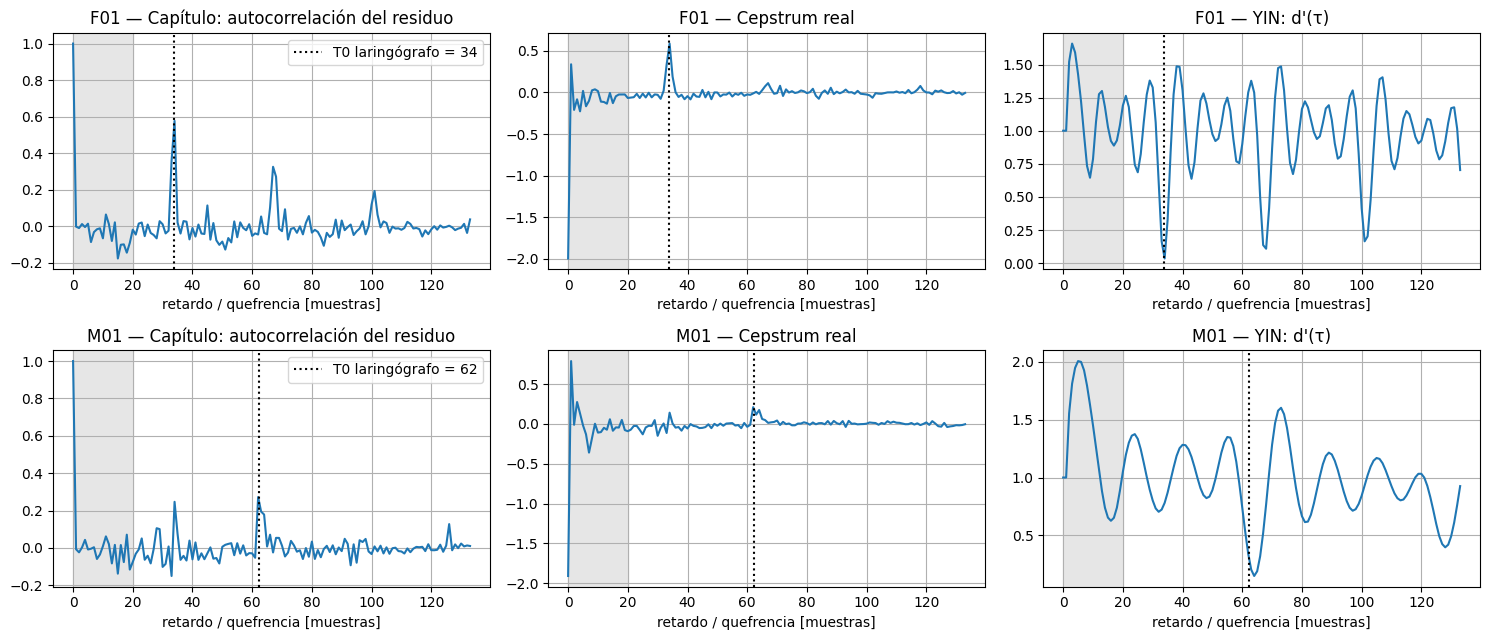

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for fila, (h, frase) in enumerate(ESCUCHAR):
    speech, f0_ref = cargar(h, frase)
    n, segs = tramas(speech)
    energia = np.array([np.sum(s[:L_TRAMA] ** 2) for s in segs])
    son = np.where(f0_ref[:n] > 0)[0]
    i = son[np.argmax(energia[son])]
    seg = segs[i]
    T0_ref = FS / f0_ref[i]
    k = np.arange(K_MAX + 1)

    frame = seg[:L_TRAMA] * np.hamming(L_TRAMA); a, _ = lpc(frame, P); e = lfilter(a, 1, frame)
    r = np.correlate(e, e, mode="full")[L_TRAMA - 1:][:K_MAX + 1]
    c = np.fft.irfft(np.log(np.abs(np.fft.rfft(frame, N_FFT_CEP)) + 1e-12), N_FFT_CEP)[:K_MAX + 1]
    dp = yin_dprima(seg)

    for ax, y, titulo in zip(axes[fila], [r / r[0], c, dp],
                             ["Capítulo: autocorrelación del residuo", "Cepstrum real", "YIN: d'(τ)"]):
        ax.plot(k, y); ax.axvline(T0_ref, color="k", ls=":", label=f"T0 laringógrafo = {T0_ref:.0f}")
        ax.axvspan(0, K_MIN, color="0.9")
        ax.set_title(f"{h} — {titulo}"); ax.set_xlabel("retardo / quefrencia [muestras]")
    axes[fila][0].legend()
    T_cap, _ = est_capitulo(seg); T_cep, _ = est_cepstrum(seg); T_yin, _ = est_yin(seg, 0.2)
    print(f"{h}: referencia {f0_ref[i]:.0f} Hz | capítulo {FS / T_cap:.0f} Hz | cepstrum {FS / T_cep:.0f} Hz | "
          f"YIN {FS / T_yin if T_yin else 0:.0f} Hz")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_tres_metodos_una_trama.png", dpi=120, bbox_inches="tight"); plt.show()

## 4. Métricas y calibración de umbrales

Las métricas se calculan **acumulando tramas** de todas las grabaciones de un grupo (por ejemplo, todas las de mujeres),
no promediando porcentajes por archivo. La trama $i$ del método se compara con la fila $i$ de la referencia (en el
notebook 01 se verificó que el desfase óptimo es 0).

Para elegir el umbral sonoro/sordo de cada método se usa el **FFE** (*F0 frame error*, Chu & Alwan, 2009): el % de tramas
con error de decisión sonoro/sordo **o** con error grueso de pitch. Combina VDE y GPE en un solo número, así el umbral no
favorece a una métrica a costa de la otra. Se elige el umbral con menor FFE en el **conjunto de calibración**.

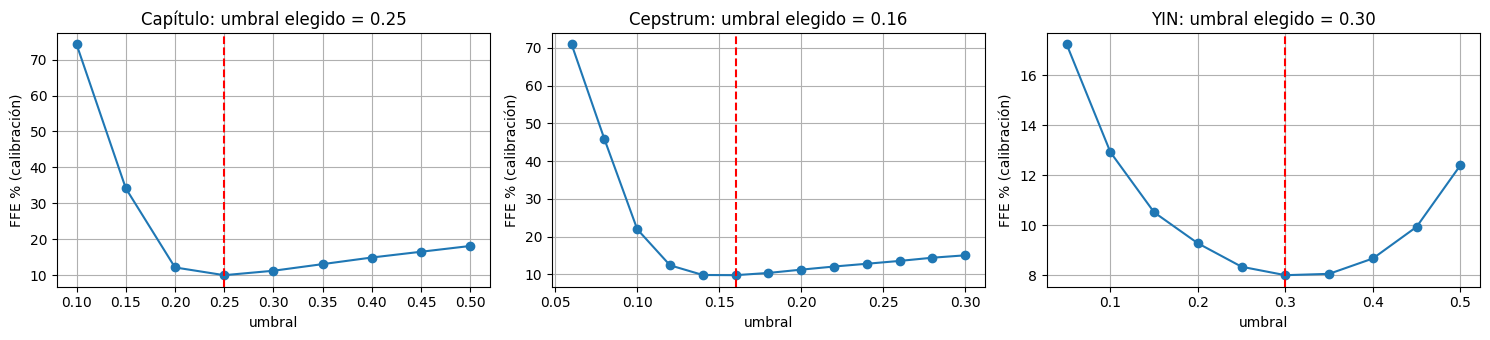

Umbrales elegidos: {'Capítulo': 0.25, 'Cepstrum': 0.16, 'YIN': 0.3}


In [ ]:
def acumular(pares):
    # pares: lista de (f0_est, f0_ref) -> métricas acumuladas sobre todas las tramas
    est = np.concatenate([e[:min(len(e), len(r))] for e, r in pares])
    ref = np.concatenate([r[:min(len(e), len(r))] for e, r in pares])
    v_est, v_ref = est > 0, ref > 0
    ambas = v_est & v_ref
    rel = (est[ambas] - ref[ambas]) / ref[ambas]
    grueso = np.abs(rel) > 0.2
    return {
        "VDE %": 100 * np.mean(v_est != v_ref),
        "GPE %": 100 * np.mean(grueso),
        "FPE %": 100 * np.std(rel[~grueso]),
        "FFE %": 100 * (np.sum(v_est != v_ref) + np.sum(grueso)) / len(ref),
        "tramas": len(ref),
    }

def f0_desde(T0s, puntajes, umbral):
    T0s, puntajes = np.asarray(T0s), np.asarray(puntajes)
    return np.where((puntajes > umbral) & (T0s > 0), FS / np.maximum(T0s, 1e-9), 0.0)

# Precalcular T0 y puntaje de capítulo y cepstrum (no dependen del umbral). YIN sí depende: se recalcula.
def precalcular(pares_hf):
    datos = []
    for h, frase in pares_hf:
        speech, f0_ref = cargar(h, frase)
        n, segs = tramas(speech)
        cap = np.array([est_capitulo(s) for s in segs])
        cep = np.array([est_cepstrum(s) for s in segs])
        datos.append({"h": h, "frase": frase, "ref": f0_ref, "segs": segs, "cap": cap, "cep": cep})
    return datos

cal = precalcular(cal_set)

GRILLAS = {
    "Capítulo": np.arange(0.10, 0.51, 0.05),
    "Cepstrum": np.arange(0.06, 0.31, 0.02),
    "YIN": np.arange(0.05, 0.51, 0.05),
}

def f0_metodo(d, metodo, umbral):
    if metodo == "Capítulo":
        return f0_desde(d["cap"][:, 0], d["cap"][:, 1], umbral)
    if metodo == "Cepstrum":
        return f0_desde(d["cep"][:, 0], d["cep"][:, 1], umbral)
    T = np.array([est_yin(s, umbral)[0] for s in d["segs"]])
    return np.where(T > 0, FS / np.maximum(T, 1e-9), 0.0)

UMBRAL = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (metodo, grilla) in zip(axes, GRILLAS.items()):
    ffe = [acumular([(f0_metodo(d, metodo, u), d["ref"]) for d in cal])["FFE %"] for u in grilla]
    UMBRAL[metodo] = float(grilla[int(np.argmin(ffe))])
    ax.plot(grilla, ffe, "o-"); ax.axvline(UMBRAL[metodo], color="r", ls="--")
    ax.set_title(f"{metodo}: umbral elegido = {UMBRAL[metodo]:.2f}"); ax.set_xlabel("umbral"); ax.set_ylabel("FFE % (calibración)")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_calibracion_umbrales.png", dpi=120, bbox_inches="tight"); plt.show()
print("Umbrales elegidos:", {k: round(v, 2) for k, v in UMBRAL.items()})

## 5. Evaluación: mujeres vs hombres

200 grabaciones (10 mujeres y 10 hombres × 10 frases), con los umbrales fijados en la calibración.

In [ ]:
ev = precalcular(eval_set)
METODOS = ["Capítulo", "Cepstrum", "YIN"]
for d in ev:
    d["f0"] = {m: f0_metodo(d, m, UMBRAL[m]) for m in METODOS}

filas = []
for m in METODOS:
    for sx, nombre in [("F", "Mujeres"), ("M", "Hombres"), (None, "Todos")]:
        grupo = [d for d in ev if sx is None or d["h"].startswith(sx)]
        filas.append({"Método": m, "Grupo": nombre, **acumular([(d["f0"][m], d["ref"]) for d in grupo])})
tabla = pd.DataFrame(filas).set_index(["Método", "Grupo"])
tabla[["VDE %", "GPE %", "FPE %", "FFE %"]] = tabla[["VDE %", "GPE %", "FPE %", "FFE %"]].round(2)
tabla.to_csv("../results/02_metricas_por_sexo.csv")
tabla

VDE %  GPE %  FPE %  FFE %  tramas
Método   Grupo                                      
Capítulo Mujeres   5.88   3.11   1.84   6.46   72180
         Hombres  11.35   1.94   1.95  11.59   70638
         Todos     8.59   2.65   1.88   9.00  142818
Cepstrum Mujeres   5.62   2.29   1.85   6.05   72180
         Hombres  11.82   0.95   1.95  11.93   70638
         Todos     8.68   1.78   1.89   8.96  142818
YIN      Mujeres   4.88   3.56   1.49   5.60   72180
         Hombres   6.71   1.58   1.52   6.97   70638
         Todos     5.78   2.67   1.50   6.28  142818

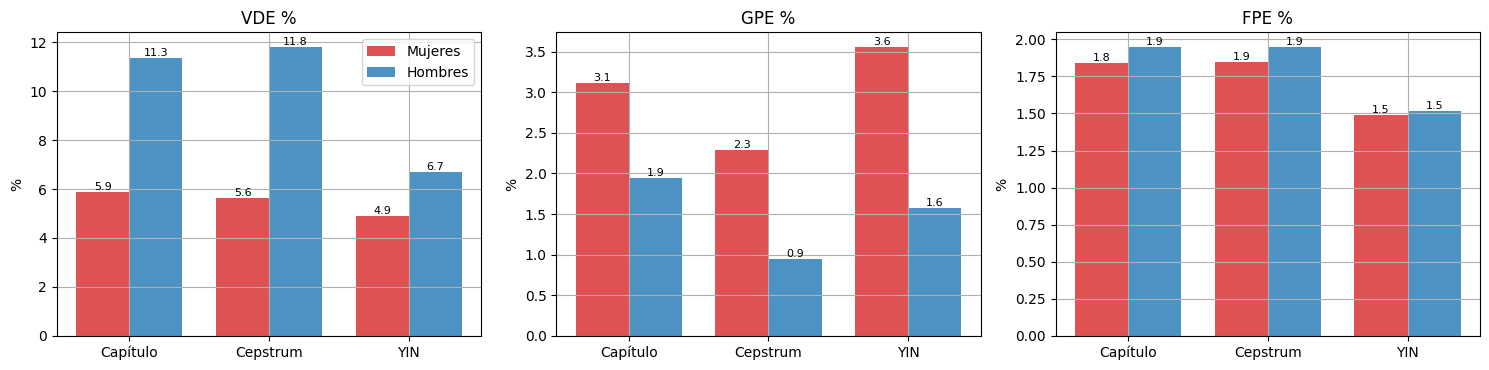

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
x = np.arange(len(METODOS)); ancho = 0.38
for ax, met in zip(axes, ["VDE %", "GPE %", "FPE %"]):
    for j, (grupo, color) in enumerate([("Mujeres", "tab:red"), ("Hombres", "tab:blue")]):
        vals = [tabla.loc[(m, grupo), met] for m in METODOS]
        barras = ax.bar(x + (j - 0.5) * ancho, vals, ancho, label=grupo, color=color, alpha=0.8)
        ax.bar_label(barras, fmt="%.1f", fontsize=8)
    ax.set_xticks(x, METODOS); ax.set_title(met); ax.set_ylabel("%")
axes[0].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "02_metricas_por_sexo.png", dpi=120, bbox_inches="tight"); plt.show()

### 5.1 ¿Qué tipo de errores gruesos comete cada método?

El capítulo advierte que en voces femeninas el segundo armónico puede tomarse como F0 (error de **octava arriba**,
$F0_{est} \approx 2\,F0_{ref}$). El error contrario (**octava abajo**, $\approx F0_{ref}/2$) aparece cuando el método elige
dos períodos en lugar de uno. Se clasifican los errores gruesos según el cociente $F0_{est}/F0_{ref}$.

In [ ]:
filas = []
for m in METODOS:
    for sx, nombre in [("F", "Mujeres"), ("M", "Hombres")]:
        cociente = []
        for d in ev:
            if not d["h"].startswith(sx):
                continue
            e, r = d["f0"][m], d["ref"]; n = min(len(e), len(r)); e, r = e[:n], r[:n]
            ambas = (e > 0) & (r > 0)
            q = e[ambas] / r[ambas]
            cociente.append(q[np.abs(q - 1) > 0.2])
        q = np.concatenate(cociente)
        filas.append({"Método": m, "Grupo": nombre, "errores gruesos": len(q),
                      "octava arriba (~2x) %": round(100 * np.mean(np.abs(q - 2) < 0.2), 1) if len(q) else np.nan,
                      "octava abajo (~0.5x) %": round(100 * np.mean(np.abs(q - 0.5) < 0.1), 1) if len(q) else np.nan})
pd.DataFrame(filas).set_index(["Método", "Grupo"])

errores gruesos  octava arriba (~2x) %  \
Método   Grupo                                             
Capítulo Mujeres              421                   30.6   
         Hombres              169                   39.1   
Cepstrum Mujeres              311                   36.7   
         Hombres               78                   29.5   
YIN      Mujeres              519                   69.0   
         Hombres              188                   78.7   

                  octava abajo (~0.5x) %  
Método   Grupo                            
Capítulo Mujeres                    56.8  
         Hombres                     0.0  
Cepstrum Mujeres                    47.3  
         Hombres                     2.6  
YIN      Mujeres                    25.0  
         Hombres                     6.4

## 6. Contornos de F0: un ejemplo de mujer y uno de hombre

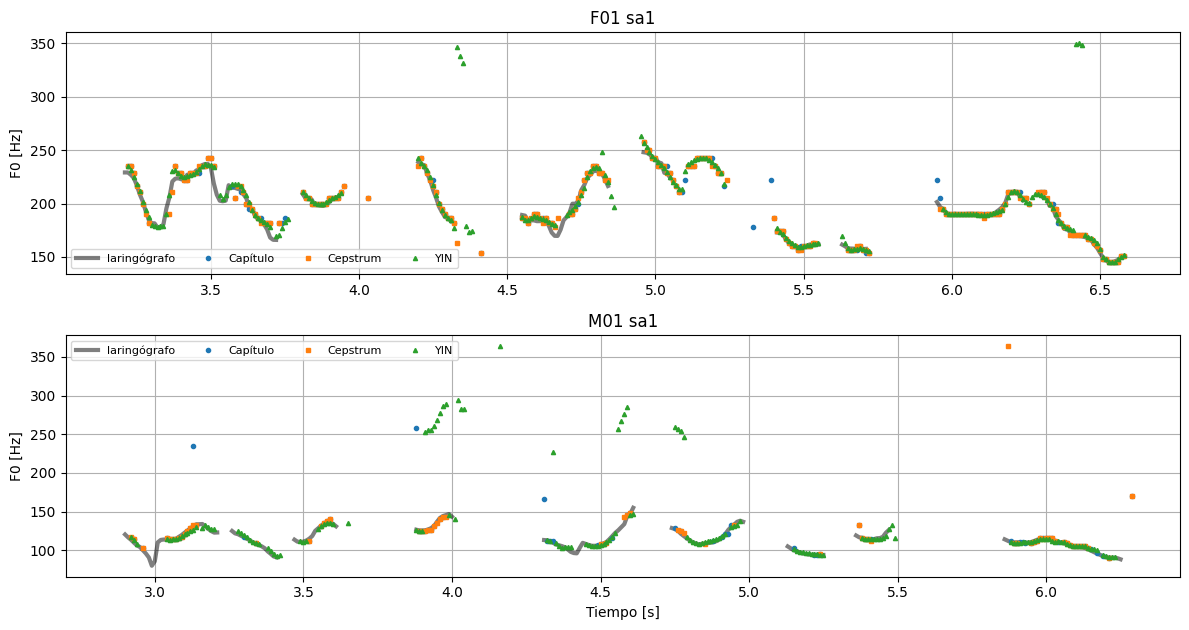

In [ ]:
fig, axes = plt.subplots(len(ESCUCHAR), 1, figsize=(12, 3.2 * len(ESCUCHAR)))
for ax, (h, frase) in zip(np.atleast_1d(axes), ESCUCHAR):
    d = next(d for d in ev if d["h"] == h and d["frase"] == frase)
    t = np.arange(len(d["ref"])) * SALTO / FS
    ax.plot(t, np.where(d["ref"] > 0, d["ref"], np.nan), "k", lw=3, alpha=0.5, label="laringógrafo")
    for m, mk in zip(METODOS, ["o", "s", "^"]):
        f = d["f0"][m]; tt = np.arange(len(f)) * SALTO / FS
        ax.plot(tt, np.where(f > 0, f, np.nan), mk, ms=3, label=m)
    voz = np.where(d["ref"] > 0)[0]
    ax.set_xlim(t[voz[0]] - 0.2, t[voz[-1]] + 0.2)
    ax.set_title(f"{h} {frase}"); ax.set_ylabel("F0 [Hz]"); ax.legend(ncol=4, fontsize=8)
np.atleast_1d(axes)[-1].set_xlabel("Tiempo [s]")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_contornos_f0.png", dpi=120, bbox_inches="tight"); plt.show()

## 7. Cada estimador dentro del decodificador LPC10

Se resintetiza la misma frase con el decodificador del capítulo cambiando **solo** la F0 y la decisión sonoro/sordo. Los
coeficientes LPC (tracto vocal) son los mismos en las cuatro versiones, así que las diferencias que se escuchan se deben
únicamente al estimador. La versión con la F0 del laringógrafo es la mejor posible con este codificador.

In [ ]:
def guardar(nombre, x):
    wavfile.write(AUDIO_DIR / nombre, FS, (0.9 * x / np.max(np.abs(x)) * 32767).astype(np.int16))

for h, frase in ESCUCHAR:
    d = next(d for d in ev if d["h"] == h and d["frase"] == frase)
    speech, _ = cargar(h, frase)
    n = len(d["segs"])
    print(f"===== {h} {frase} =====")
    print("Original:"); display(Audio(speech, rate=FS))
    versiones = {**{m: d["f0"][m] for m in METODOS}, "Laringógrafo": d["ref"][:n]}
    for nombre, f0 in versiones.items():
        np.random.seed(0)                          # misma excitación sorda en todas las versiones
        y = lpc10(speech, f0)
        print(f"LPC10 con F0 de {nombre}:"); display(Audio(y, rate=FS))
        guardar(f"{h}_{frase}_lpc10_{nombre.lower().replace('í', 'i').replace('ó', 'o')}.wav", y)

===== F01 sa1 =====
Original:


LPC10 con F0 de Capítulo:


LPC10 con F0 de Cepstrum:


LPC10 con F0 de YIN:


LPC10 con F0 de Laringógrafo:


...


Original:


LPC10 con F0 de Capítulo:


LPC10 con F0 de Cepstrum:


LPC10 con F0 de YIN:


LPC10 con F0 de Laringógrafo:


## 8. Conclusiones

- YIN decide mejor si hay voz, sobre todo en hombres, y es el más preciso.
- Cepstrum comete menos errores gruesos.
- El método del capítulo no gana en ninguna métrica; su punto débil es decidir sonoro/sordo en voces graves.
- El capítulo advierte errores de “octava arriba” en mujeres, pero en nuestros datos su método falla más con “octava abajo”.
- Las diferencias en las métricas no tienen un efecto notorio sobre la voz resintetizada al ser escuchada por los integrantes del grupo.


_Es posible que haya pequeñas diferencias ya que estamos analizando únicamente una muestra de femenino y una de masculino. Pero los resultados iniciales son alentadores._


**Limitaciones:** los umbrales se calibraron con 40 grabaciones; la referencia (RAPT sobre el laringógrafo) también
tiene errores propios; los tres métodos usan la misma trama de 30 ms del codificador, que para voces muy graves
contiene menos de dos períodos.